# Alerta Criadouro - Machine Learning: risco de dengue da próxima semana

**Global Solution 2026.2 - FIAP - Tecnólogo em Inteligência Artificial - turma 1TIAPZ**
**Matéria:** Machine Learning & Modelling

| Integrante | RM |
|---|---|
| Matheus Rebelo | 570260 |
| Felipe Olmos | 570946 |
| Luiz Guilherme | 573486 |

Repositório: https://github.com/matheusrebelo04-maker/alerta-criadouro

## 1. Problema, público e objetivo

Cerca de 75% dos focos do mosquito da dengue ficam dentro das casas (governo de SP, via Poder360, fev/2026). Em 2024 o Brasil teve 6,48 milhões de casos prováveis e 5.972 mortes, o pior ano da história. Na cidade de São Paulo foram mais de 1,2 milhão de casos notificados.

**Público:** famílias que moram em casas com quintal em bairros da cidade de São Paulo. Elas usam o Alerta Criadouro, um aparelho com ESP32 que avisa quando o potinho sentinela do quintal está com água parada há dias.

**Onde entra o Machine Learning:** o aparelho sabe o que acontece no quintal, mas não sabe como está a dengue na cidade. O modelo responde uma pergunta simples, toda semana:

> **A próxima semana vai ser de risco alto de dengue em São Paulo (nível laranja ou vermelho do InfoDengue)?**

Com essa resposta, o aparelho e o app podem ficar mais insistentes nas semanas perigosas. Por exemplo: se o risco da cidade é alto e o potinho está com água, o aviso sobe de ATENÇÃO para ALERTA mais cedo.

É uma tarefa de **classificação binária**: 1 = risco alto (nível 3 ou 4), 0 = risco baixo ou moderado (nível 1 ou 2).

## 2. Base de dados

Fonte: **InfoDengue** (Fiocruz e FGV), que junta as notificações de dengue do SINAN com dados de clima. Dados semanais da cidade de São Paulo (código IBGE 3550308), de 2015 a 2025. São dados reais e públicos.

Antes de usar a base, conferimos o hash SHA-256. Se o arquivo tiver sido alterado (por erro ou de propósito), o notebook para. É uma proteção do modelo contra dados envenenados, explicada no relatório de Cybersecurity.

In [1]:
import hashlib, os, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

ARQUIVO = "../dados/infodengue_sp_2015_2025.csv"
URL_GITHUB = "https://raw.githubusercontent.com/matheusrebelo04-maker/alerta-criadouro/main/dados/infodengue_sp_2015_2025.csv"
if not os.path.exists(ARQUIVO):          # no Colab baixa do nosso GitHub
    ARQUIVO = "infodengue_sp_2015_2025.csv"
    urllib.request.urlretrieve(URL_GITHUB, ARQUIVO)

HASH_ESPERADO = "741ccfb2a01cf5d98614fcffd4ddfaf41a748b4b0549211435879c1bec97a03b"
hash_atual = hashlib.sha256(open(ARQUIVO, "rb").read()).hexdigest()
assert hash_atual == HASH_ESPERADO, "Base alterada! Treino cancelado."
print("Hash conferido, base íntegra:", hash_atual)

dados = pd.read_csv(ARQUIVO)
dados["data"] = pd.to_datetime(dados["data_iniSE"])
dados = dados.sort_values("data").reset_index(drop=True)
print(dados.shape)
dados[["data", "SE", "casos", "p_inc100k", "Rt", "nivel", "tempmed", "umidmed", "umidmax"]].head()

Hash conferido, base íntegra: 741ccfb2a01cf5d98614fcffd4ddfaf41a748b4b0549211435879c1bec97a03b
(574, 31)


,data,SE,casos,p_inc100k,Rt,nivel,tempmed,umidmed,umidmax
0,2015-01-04,201501,370,3.001972,3.434149,2,24.870866,66.828678,84.714286
1,2015-01-11,201502,389,3.156127,2.371683,3,25.901172,65.288701,86.000000
2,2015-01-18,201503,640,5.192600,2.166121,3,24.482563,67.620550,85.857143
3,2015-01-25,201504,870,7.058690,1.933723,3,23.355853,70.017558,87.571429
4,2015-02-01,201505,1498,12.153930,2.266027,3,21.532317,76.673218,89.714286


Principais variáveis:

| Variável | O que é |
|---|---|
| casos | casos notificados na semana |
| p_inc100k | casos por 100 mil habitantes |
| Rt | quantas pessoas cada doente infecta (acima de 1 = crescendo) |
| nivel | nível de alerta do InfoDengue: 1 verde, 2 amarelo, 3 laranja, 4 vermelho |
| tempmin, tempmed, tempmax | temperatura da semana (°C) |
| umidmin, umidmed, umidmax | umidade do ar da semana (%) |

## 3. Análise exploratória (EDA)

In [2]:
print("Período:", dados["data"].min().date(), "a", dados["data"].max().date())
print("Semanas:", len(dados))
dados[["casos", "p_inc100k", "Rt", "nivel", "tempmin", "tempmed", "tempmax", "umidmin", "umidmed", "umidmax"]].describe().round(2).T

Período: 2015-01-04 a 2025-12-28
Semanas: 574


,count,mean,std,min,25%,50%,75%,max
casos,574.0,3380.08,11275.61,38.00,192.25,401.00,1921.50,85389.00
p_inc100k,574.0,27.67,92.42,0.31,1.56,3.25,15.62,699.90
Rt,574.0,1.07,0.44,0.14,0.81,0.99,1.21,4.60
nivel,574.0,2.13,1.26,1.00,1.00,2.00,3.00,4.00
tempmin,574.0,16.99,2.83,9.32,14.86,17.14,19.14,22.77
tempmed,561.0,19.40,2.89,11.01,17.27,19.75,21.53,26.88
tempmax,561.0,22.86,3.81,12.00,20.14,23.14,25.57,33.50
umidmin,561.0,61.02,13.11,20.29,50.86,61.71,71.38,88.65
umidmed,561.0,77.70,7.04,46.55,73.75,78.84,82.73,91.02
umidmax,561.0,88.62,5.44,65.40,85.46,88.63,92.25,99.11


### Qualidade dos dados

In [3]:
faltando = dados.isna().sum()
print("Valores faltando por coluna:")
print(faltando[faltando > 0])
print("\nSemanas repetidas:", dados["SE"].duplicated().sum())

Valores faltando por coluna:
casos_est_max       40
umidmax             13
umidmed             13
umidmin             13
tempmed             13
tempmax             13
casprov_est        574
casprov_est_min    574
casprov_est_max    574
casconf            574
dtype: int64

Semanas repetidas: 0


Quatro colunas (casprov_est, casprov_est_min, casprov_est_max e casconf) vêm totalmente vazias e não serão usadas. Faltam temperatura média, temperatura máxima e umidades em 13 semanas, que vamos preencher com a mediana **do treino** dentro do pipeline. Não há semanas repetidas.

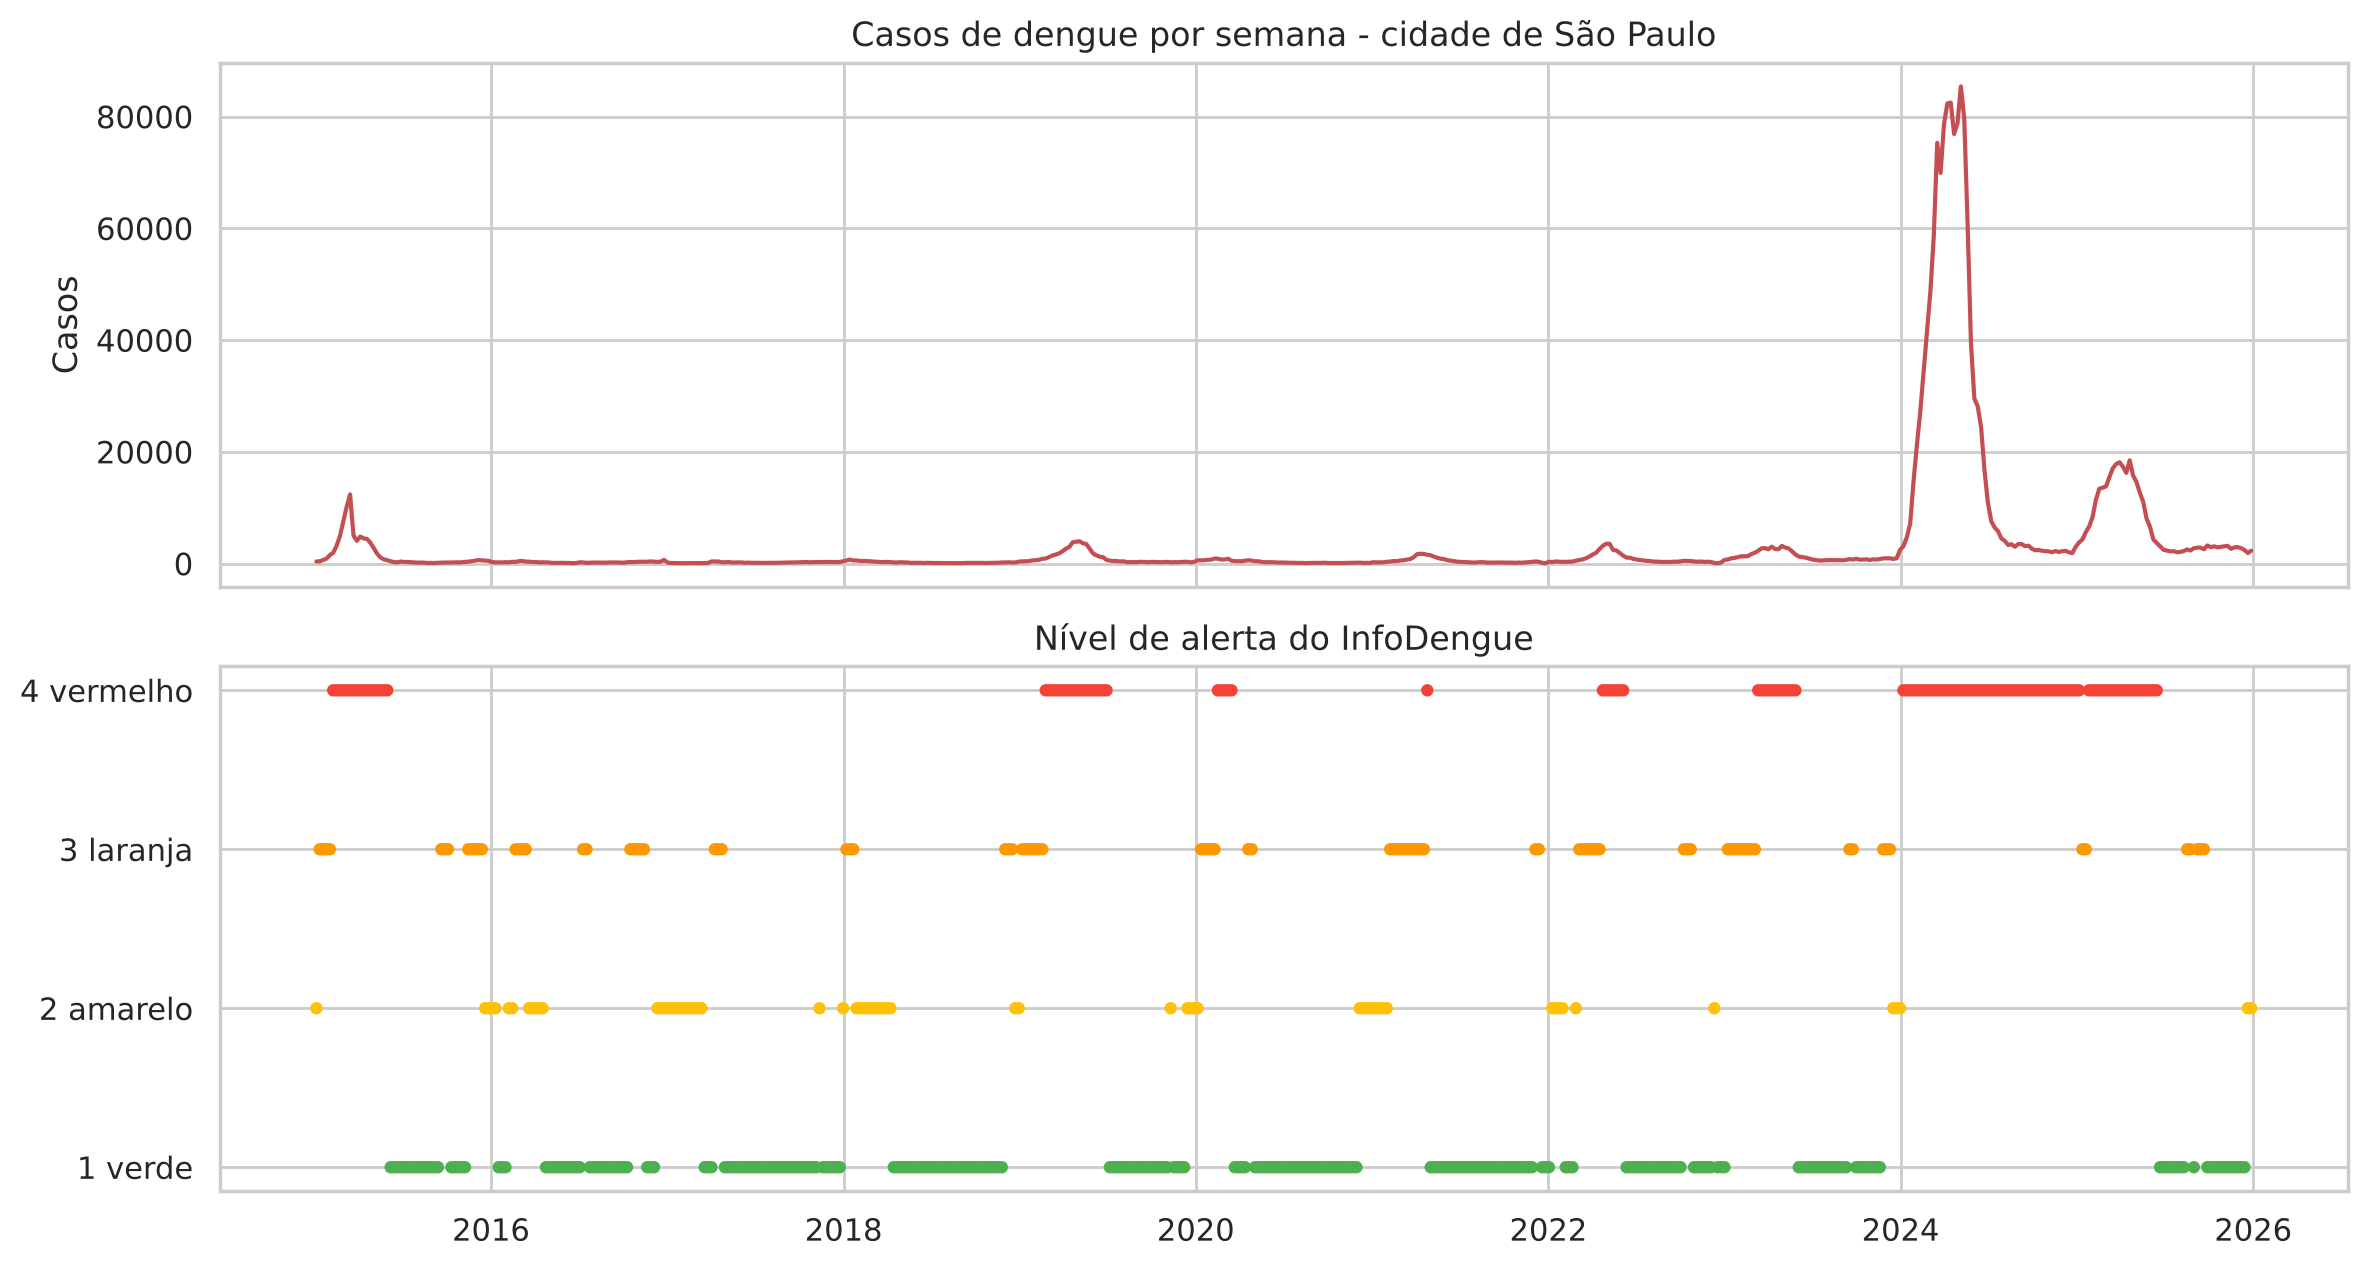

In [4]:
fig, eixos = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
eixos[0].plot(dados["data"], dados["casos"], color="#C44E52")
eixos[0].set_title("Casos de dengue por semana - cidade de São Paulo")
eixos[0].set_ylabel("Casos")
cores = {1: "#4CAF50", 2: "#FFC107", 3: "#FF9800", 4: "#F44336"}
eixos[1].scatter(dados["data"], dados["nivel"], c=dados["nivel"].map(cores), s=12)
eixos[1].set_title("Nível de alerta do InfoDengue")
eixos[1].set_yticks([1, 2, 3, 4]); eixos[1].set_yticklabels(["1 verde", "2 amarelo", "3 laranja", "4 vermelho"])
plt.tight_layout(); plt.show()

Os surtos aparecem todo começo de ano (verão e outono), e 2024 foi muito acima de tudo. Os níveis altos vêm em blocos: quando a cidade entra no laranja ou vermelho, costuma ficar várias semanas. Isso mostra que o nível da semana atual já diz muito sobre a próxima, e por isso o baseline de persistência vai ser forte.

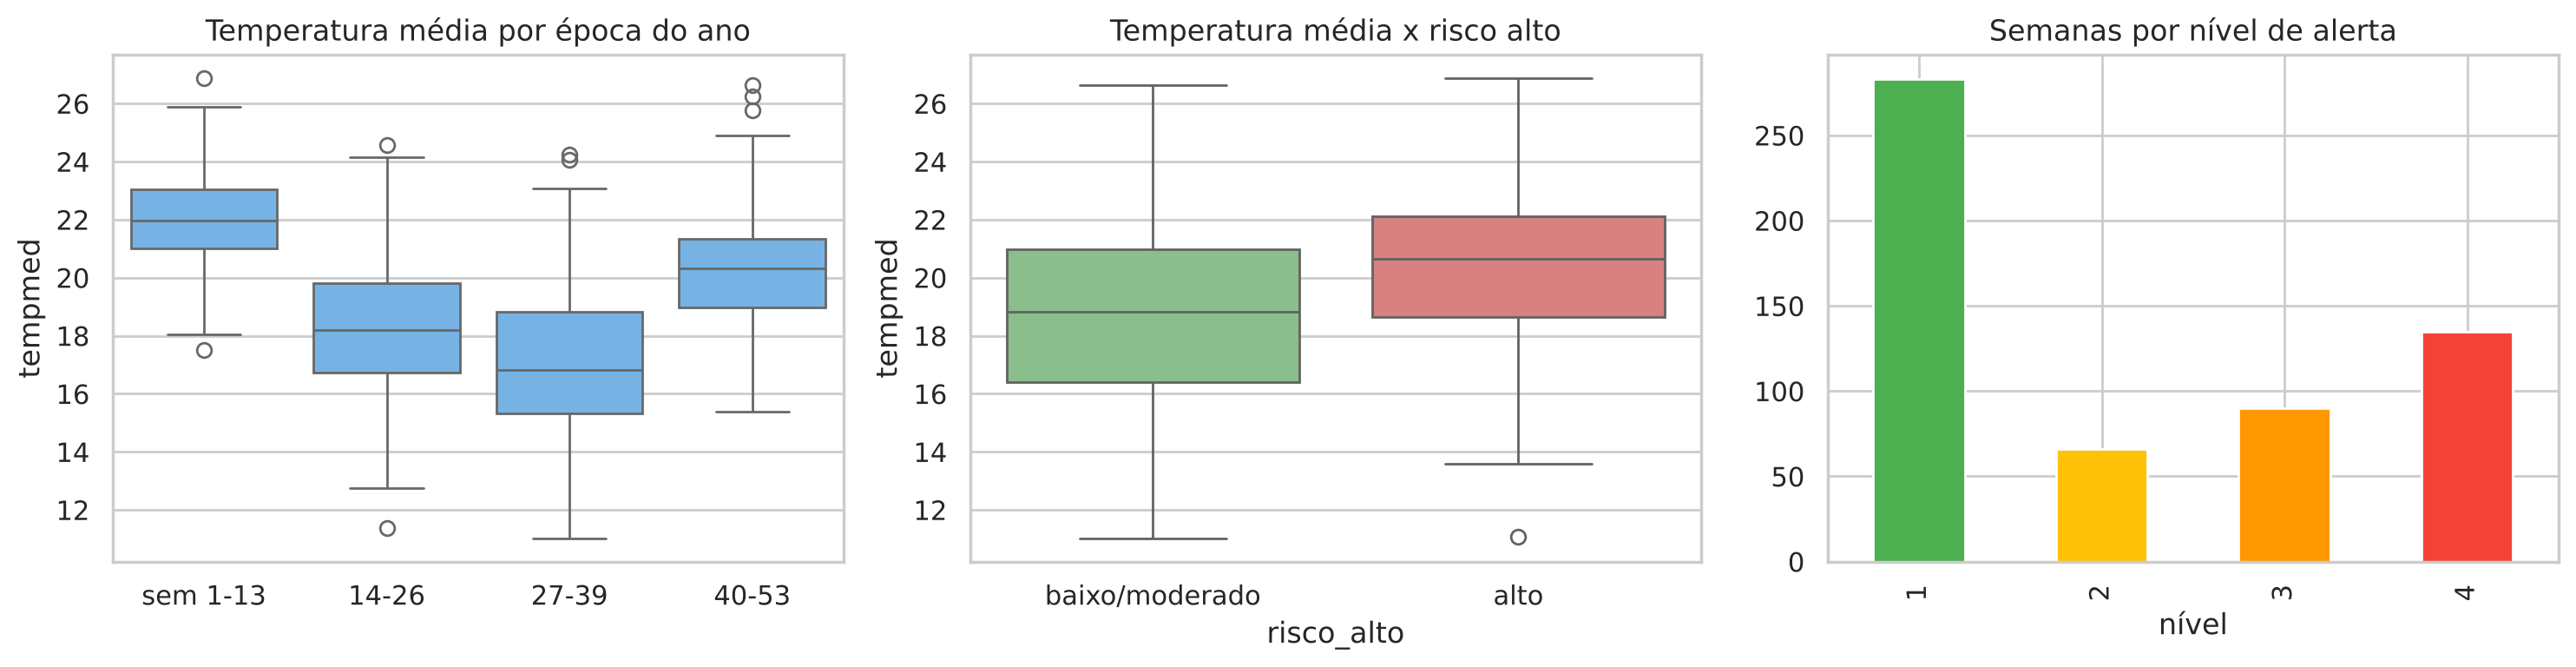

risco_alto
0    0.608
1    0.392
Name: proportion, dtype: float64


In [5]:
dados["semana_do_ano"] = dados["SE"] % 100
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=dados, x=pd.cut(dados["semana_do_ano"], [0, 13, 26, 39, 53], labels=["sem 1-13", "14-26", "27-39", "40-53"]),
            y="tempmed", ax=eixos[0], color="#64B5F6")
eixos[0].set_title("Temperatura média por época do ano"); eixos[0].set_xlabel("")
dados["risco_alto"] = (dados["nivel"] >= 3).astype(int)
sns.boxplot(data=dados, x="risco_alto", y="tempmed", ax=eixos[1], palette=["#81C784", "#E57373"])
eixos[1].set_title("Temperatura média x risco alto"); eixos[1].set_xticklabels(["baixo/moderado", "alto"])
dados["nivel"].value_counts().sort_index().plot.bar(ax=eixos[2], color=[cores[i] for i in range(1, 5)])
eixos[2].set_title("Semanas por nível de alerta"); eixos[2].set_xlabel("nível")
plt.tight_layout(); plt.show()
print(dados["risco_alto"].value_counts(normalize=True).round(3))

As semanas de risco alto têm temperatura média maior. 39% das semanas são de risco alto, então as classes não estão muito desbalanceadas na base toda.

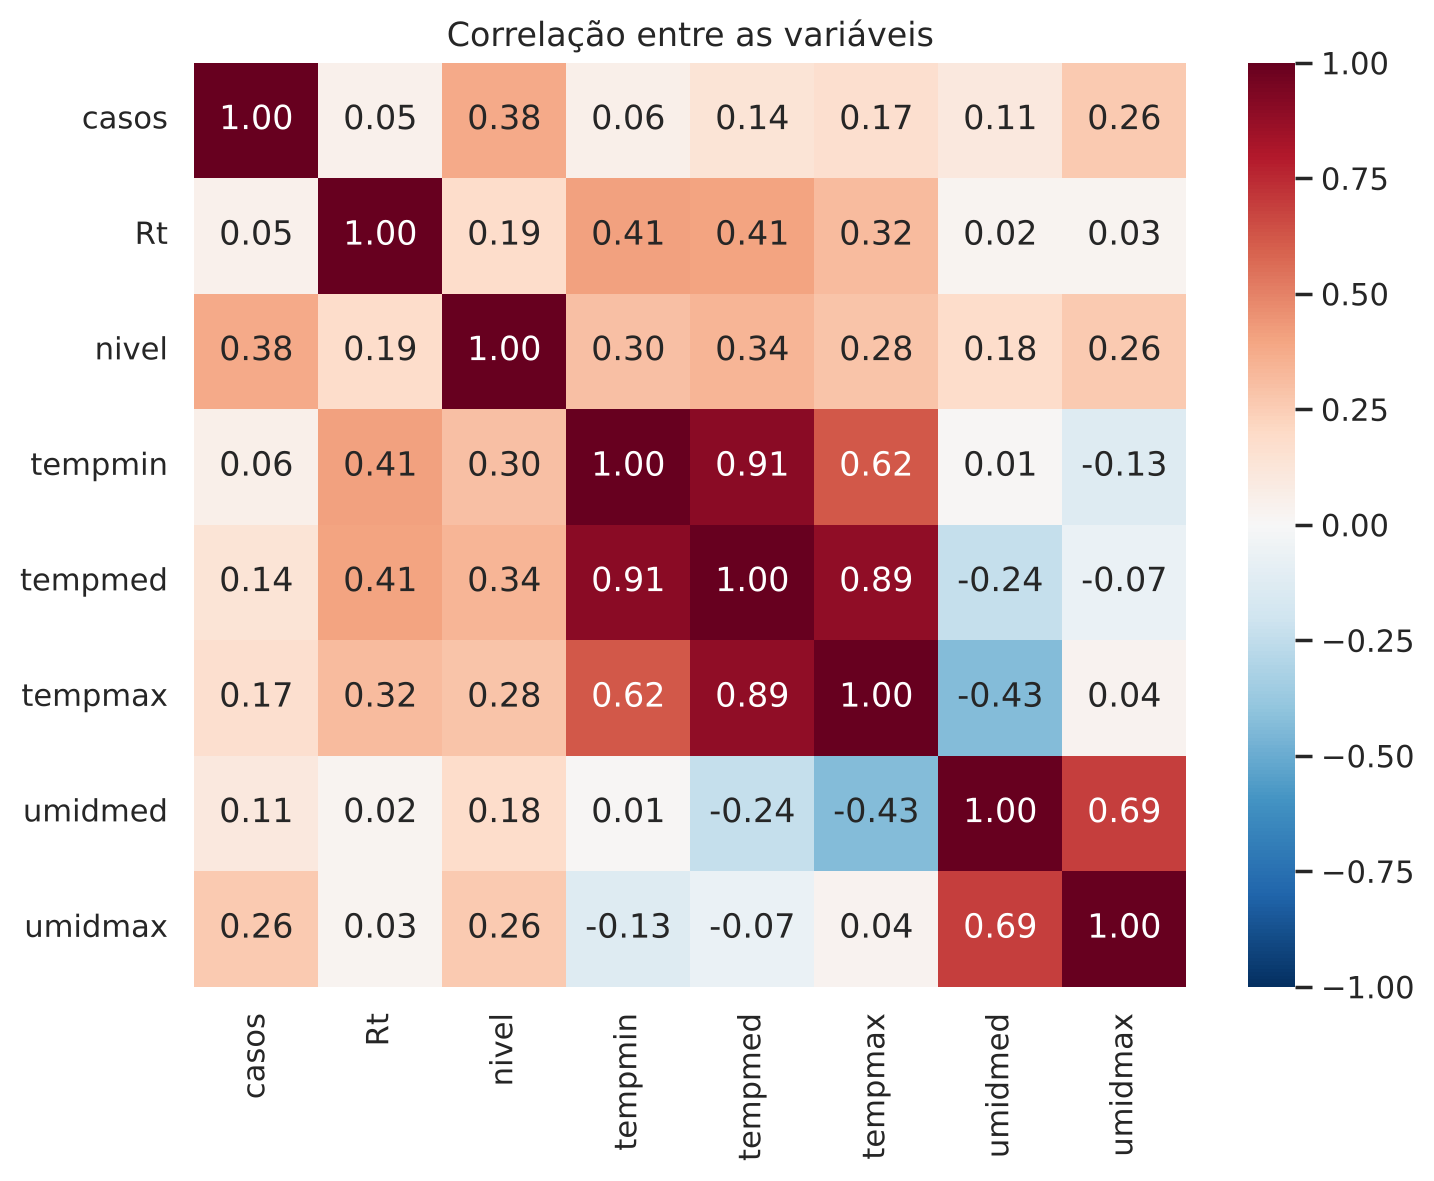

In [6]:
colunas_corr = ["casos", "Rt", "nivel", "tempmin", "tempmed", "tempmax", "umidmed", "umidmax"]
plt.figure(figsize=(8, 6))
sns.heatmap(dados[colunas_corr].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlação entre as variáveis"); plt.show()

A umidade máxima e a temperatura têm relação com o nível de alerta. O Rt também se relaciona com a temperatura, como vimos no relatório de Estatística.

## 4. Pré-processamento

**Cuidado com o vazamento de dados (data leakage):**

1. O nível do InfoDengue é calculado a partir dos casos da própria semana. Se usássemos os casos da semana para prever o nível da mesma semana, o modelo estaria colando. Por isso o alvo é o nível da **semana seguinte**, e todas as variáveis são da semana atual ou de semanas anteriores.
2. A divisão é **por tempo**, nunca aleatória: o treino vai de 2015 a 2022 e o teste de 2023 a 2025. O modelo nunca vê o futuro durante o treino. O teste inclui a epidemia recorde de 2024, um desafio de verdade.
3. O preenchimento dos valores faltando (mediana) e a padronização (StandardScaler) ficam **dentro de um Pipeline**. Assim eles aprendem só com os dados de treino, inclusive dentro de cada dobra da validação cruzada.

**Engenharia de atributos** (tudo conhecido na semana atual):

- casos em escala log (log de 1 + casos), da semana atual e das 2 anteriores, e a variação de uma semana para outra;
- Rt atual e da semana anterior, incidência por 100 mil e nível atual;
- temperatura e umidade da semana e a média das últimas 4 semanas (o mosquito reage ao clima com atraso);
- semana do ano em seno e cosseno, para o modelo entender que a semana 52 fica perto da semana 1.

In [7]:
def criar_atributos(base):
    f = pd.DataFrame({"data": base["data"]})
    log_casos = np.log1p(base["casos"])
    f["log_casos"] = log_casos
    f["log_casos_1"] = log_casos.shift(1)
    f["log_casos_2"] = log_casos.shift(2)
    f["variacao_casos"] = f["log_casos"] - f["log_casos_1"]
    f["rt"] = base["Rt"]
    f["rt_1"] = base["Rt"].shift(1)
    f["incidencia"] = base["p_inc100k"]
    f["nivel_atual"] = base["nivel"]
    for c in ["tempmed", "tempmin", "umidmed", "umidmax"]:
        f[c] = base[c]
        f[c + "_media4"] = base[c].rolling(4, min_periods=1).mean()
    semana = base["SE"] % 100
    f["semana_sin"] = np.sin(2 * np.pi * semana / 52)
    f["semana_cos"] = np.cos(2 * np.pi * semana / 52)
    return f

atributos = criar_atributos(dados)
atributos["alvo"] = (dados["nivel"].shift(-1) >= 3).astype(float)   # risco alto na PRÓXIMA semana
atributos.loc[dados["nivel"].shift(-1).isna(), "alvo"] = np.nan
atributos = atributos.dropna(subset=["alvo", "log_casos_2"]).reset_index(drop=True)
atributos["alvo"] = atributos["alvo"].astype(int)

COLUNAS = [c for c in atributos.columns if c not in ("data", "alvo")]
treino = atributos[atributos["data"] < "2023-01-01"]
teste = atributos[atributos["data"] >= "2023-01-01"]
X_treino, y_treino = treino[COLUNAS], treino["alvo"]
X_teste, y_teste = teste[COLUNAS], teste["alvo"]
print("Atributos:", len(COLUNAS))
print(f"Treino: {len(treino)} semanas ({treino['data'].min().date()} a {treino['data'].max().date()}) - risco alto em {y_treino.mean():.1%}")
print(f"Teste:  {len(teste)} semanas ({teste['data'].min().date()} a {teste['data'].max().date()}) - risco alto em {y_teste.mean():.1%}")
print("Faltando no treino:", int(X_treino.isna().sum().sum()), "| no teste:", int(X_teste.isna().sum().sum()))

Atributos: 18
Treino: 415 semanas (2015-01-18 a 2022-12-25) - risco alto em 28.0%
Teste:  156 semanas (2023-01-01 a 2025-12-21) - risco alto em 68.6%
Faltando no treino: 60 | no teste: 0


O teste tem bem mais semanas de risco alto (69%) do que o treino (28%), porque 2023 a 2025 foram anos de muita dengue. Isso é uma mudança de cenário real que o modelo vai enfrentar. Por isso usamos `class_weight='balanced'` quando o algoritmo permite e olhamos F1 e recall, não só a acurácia.

## 5. Baselines

Antes dos modelos, dois jeitos simples de "prever":

- **Classe mais comum:** sempre dizer "risco baixo" (o que mais aparece no treino).
- **Persistência:** dizer que a próxima semana vai ser igual à atual. É o que uma pessoa faria olhando o painel do InfoDengue. Qualquer modelo precisa bater isso para valer a pena.

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

def metricas(nome, y_real, y_prev, y_prob=None):
    return {"modelo": nome,
            "acurácia": accuracy_score(y_real, y_prev),
            "precisão": precision_score(y_real, y_prev, zero_division=0),
            "recall": recall_score(y_real, y_prev),
            "F1": f1_score(y_real, y_prev),
            "AUC": roc_auc_score(y_real, y_prob) if y_prob is not None else np.nan}

dummy = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
prev_persistencia = (X_teste["nivel_atual"] >= 3).astype(int)
resultados = [metricas("Baseline: classe mais comum", y_teste, dummy.predict(X_teste)),
              metricas("Baseline: persistência", y_teste, prev_persistencia)]
pd.DataFrame(resultados).round(3)

,modelo,acurácia,precisão,recall,F1,AUC
0,Baseline: classe mais comum,0.314,0.000,0.000,0.000,NaN
1,Baseline: persistência,0.923,0.944,0.944,0.944,NaN


A persistência já acerta 92%. Isso confirma o que vimos na EDA: o risco muda devagar. O ponto fraco dela é que **nunca avisa uma virada**: ela só percebe que o risco ficou alto uma semana depois. É aí que o Machine Learning pode ajudar.

## 6. Modelos

Escolhemos três algoritmos estudados na disciplina, com jeitos diferentes de aprender:

- **Regressão Logística:** modelo linear simples e fácil de explicar. Precisa das variáveis padronizadas. Serve para ver se uma fronteira simples já resolve.
- **Random Forest:** muitas árvores de decisão votando. Pega relações não lineares (por exemplo, calor só importa quando já há casos) e é resistente a overfitting.
- **XGBoost:** árvores construídas uma corrigindo o erro da anterior (boosting). Costuma ser o mais forte em dados de tabela.

Todos ficam dentro do mesmo Pipeline (mediana para faltantes, padronização e modelo). As árvores não precisam de padronização, mas manter o mesmo pipeline deixa a comparação justa e não atrapalha.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def montar(modelo):
    return Pipeline([("faltantes", SimpleImputer(strategy="median")),
                     ("padronizacao", StandardScaler()),
                     ("modelo", modelo)])

proporcao = (y_treino == 0).sum() / (y_treino == 1).sum()
modelos = {
    "Regressão Logística": montar(LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Random Forest": montar(RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=42)),
    "XGBoost": montar(XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, scale_pos_weight=proporcao,
                                    random_state=42, eval_metric="logloss")),
}
comparacao = []
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    r_tr = metricas(nome + " (treino)", y_treino, modelo.predict(X_treino), modelo.predict_proba(X_treino)[:, 1])
    r_te = metricas(nome + " (teste)", y_teste, modelo.predict(X_teste), modelo.predict_proba(X_teste)[:, 1])
    comparacao += [r_tr, r_te]
pd.DataFrame(comparacao).round(3)

,modelo,acurácia,precisão,recall,F1,AUC
0,Regressão Logística (treino),0.945,0.860,0.957,0.906,0.984
1,Regressão Logística (teste),0.827,0.808,0.981,0.886,0.978
2,Random Forest (treino),0.988,0.959,1.000,0.979,1.000
3,Random Forest (teste),0.923,0.928,0.963,0.945,0.969
4,XGBoost (treino),1.000,1.000,1.000,1.000,1.000
5,XGBoost (teste),0.936,0.945,0.963,0.954,0.940


Sem tuning, o XGBoost acerta 100% no treino, sinal claro de que ele está decorando (overfitting). A Regressão Logística tem recall alto, mas erra muito para cima (muitos alarmes falsos). O Random Forest fica no meio. Vamos ajustar os hiperparâmetros.

## 7. Tuning de hiperparâmetros

Usamos **GridSearchCV** com **TimeSeriesSplit** (5 dobras). Na validação por tempo cada dobra treina com o passado e valida com o período logo depois, igual ao uso real. Uma validação aleatória (KFold comum) misturaria semanas do futuro no treino.

A métrica de escolha é o **F1**, que equilibra não perder semanas de risco (recall) e não dar alarme falso demais (precisão).

In [10]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
validacao = TimeSeriesSplit(n_splits=5)

grade_rf = {"modelo__n_estimators": [200, 400],
            "modelo__max_depth": [3, 5, None],
            "modelo__min_samples_leaf": [1, 3, 5],
            "modelo__max_features": ["sqrt", 0.5]}
busca_rf = GridSearchCV(montar(RandomForestClassifier(class_weight="balanced", random_state=42)),
                        grade_rf, cv=validacao, scoring="f1", n_jobs=-1)
busca_rf.fit(X_treino, y_treino)
print("Random Forest - melhores parâmetros:", busca_rf.best_params_)
print("F1 médio na validação cruzada:", round(busca_rf.best_score_, 3))

grade_xgb = {"modelo__n_estimators": [100, 300],
             "modelo__max_depth": [2, 3, 4],
             "modelo__learning_rate": [0.03, 0.1],
             "modelo__subsample": [0.8, 1.0],
             "modelo__min_child_weight": [1, 5]}
busca_xgb = GridSearchCV(montar(XGBClassifier(scale_pos_weight=proporcao, random_state=42, eval_metric="logloss")),
                         grade_xgb, cv=validacao, scoring="f1", n_jobs=-1)
busca_xgb.fit(X_treino, y_treino)
print("XGBoost - melhores parâmetros:", busca_xgb.best_params_)
print("F1 médio na validação cruzada:", round(busca_xgb.best_score_, 3))

Random Forest - melhores parâmetros: {'modelo__max_depth': 5, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 200}
F1 médio na validação cruzada: 0.885


XGBoost - melhores parâmetros: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 4, 'modelo__min_child_weight': 1, 'modelo__n_estimators': 300, 'modelo__subsample': 1.0}
F1 médio na validação cruzada: 0.911


## 8. Avaliação e análise de generalização

In [11]:
finais = {"Regressão Logística": modelos["Regressão Logística"],
          "Random Forest ajustado": busca_rf.best_estimator_,
          "XGBoost ajustado": busca_xgb.best_estimator_}
linhas = []
for nome, modelo in finais.items():
    tr = metricas(nome, y_treino, modelo.predict(X_treino), modelo.predict_proba(X_treino)[:, 1])
    te = metricas(nome, y_teste, modelo.predict(X_teste), modelo.predict_proba(X_teste)[:, 1])
    linhas.append({"modelo": nome, "F1 treino": tr["F1"], "F1 teste": te["F1"], "diferença": tr["F1"] - te["F1"],
                   "acurácia teste": te["acurácia"], "precisão teste": te["precisão"],
                   "recall teste": te["recall"], "AUC teste": te["AUC"]})
p = metricas("Baseline: persistência", y_teste, prev_persistencia)
linhas.append({"modelo": "Baseline: persistência", "F1 treino": f1_score(y_treino, (X_treino["nivel_atual"] >= 3).astype(int)),
               "F1 teste": p["F1"], "diferença": np.nan, "acurácia teste": p["acurácia"],
               "precisão teste": p["precisão"], "recall teste": p["recall"], "AUC teste": np.nan})
tabela_final = pd.DataFrame(linhas).round(3)
tabela_final

,modelo,F1 treino,F1 teste,diferença,acurácia teste,precisão teste,recall teste,AUC teste
0,Regressão Logística,0.906,0.886,0.020,0.827,0.808,0.981,0.978
1,Random Forest ajustado,0.967,0.954,0.013,0.936,0.945,0.963,0.965
2,XGBoost ajustado,1.000,0.949,0.051,0.929,0.944,0.953,0.944
3,Baseline: persistência,0.867,0.944,NaN,0.923,0.944,0.944,NaN


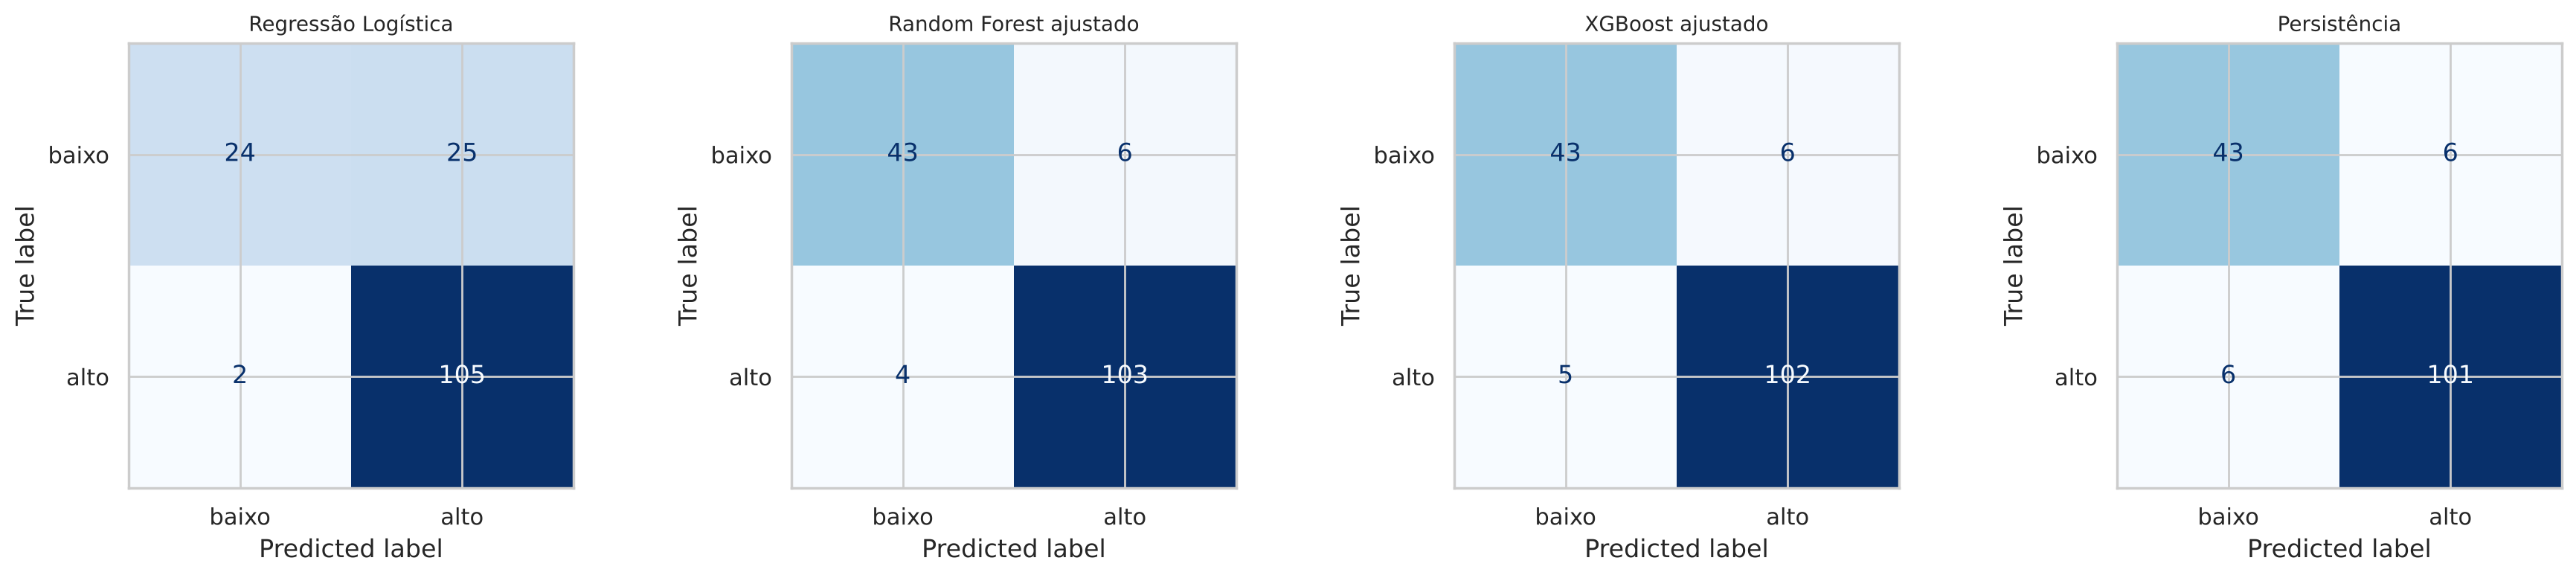

In [12]:
fig, eixos = plt.subplots(1, 4, figsize=(18, 4))
previsoes = {nome: m.predict(X_teste) for nome, m in finais.items()}
previsoes["Persistência"] = prev_persistencia.values
for eixo, (nome, prev) in zip(eixos, previsoes.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_teste, prev), display_labels=["baixo", "alto"]).plot(ax=eixo, colorbar=False, cmap="Blues")
    eixo.set_title(nome, fontsize=10)
plt.tight_layout(); plt.show()

### As viradas: o que realmente interessa

Virada é quando o risco da próxima semana é diferente do risco atual (o começo ou o fim de um surto). A persistência erra todas, por definição. Um bom modelo precisa acertar pelo menos parte delas sem perder o resto.

In [13]:
viradas = (X_teste["nivel_atual"] >= 3).astype(int).values != y_teste.values
print("Semanas de virada no teste:", viradas.sum())
for nome, prev in previsoes.items():
    acertos = (prev[viradas] == y_teste.values[viradas]).sum()
    print(f"{nome:25s} acertou {acertos} de {viradas.sum()} viradas")
tab = teste.loc[viradas, ["data", "nivel_atual"]].copy()
tab["risco_real_prox_semana"] = y_teste[viradas].map({0: "baixo", 1: "ALTO"}).values
tab["XGBoost"] = pd.Series(previsoes["XGBoost ajustado"][viradas]).map({0: "baixo", 1: "ALTO"}).values
tab["Random Forest"] = pd.Series(previsoes["Random Forest ajustado"][viradas]).map({0: "baixo", 1: "ALTO"}).values
tab

Semanas de virada no teste: 12
Regressão Logística       acertou 4 de 12 viradas
Random Forest ajustado    acertou 2 de 12 viradas
XGBoost ajustado          acertou 2 de 12 viradas
Persistência              acertou 0 de 12 viradas


,data,nivel_atual,risco_real_prox_semana,XGBoost,Random Forest
415,2023-01-01,1,ALTO,ALTO,ALTO
436,2023-05-28,4,baixo,ALTO,ALTO
451,2023-09-10,1,ALTO,baixo,baixo
453,2023-09-24,3,baixo,ALTO,ALTO
461,2023-11-19,1,ALTO,baixo,baixo
464,2023-12-10,3,baixo,ALTO,ALTO
467,2023-12-31,2,ALTO,ALTO,ALTO
543,2025-06-15,4,baixo,ALTO,ALTO
551,2025-08-10,1,ALTO,baixo,baixo
553,2025-08-24,3,baixo,ALTO,ALTO


### Escolha do modelo final

Critérios que usamos, nessa ordem:

1. **Generalizar bem**: pouca diferença entre o F1 de treino e de teste (sem decorar).
2. **F1 no teste** igual ou melhor que o da persistência.
3. **Acertar viradas**, porque é isso que dá tempo para a família agir antes do pico.

O modelo final é escolhido automaticamente na célula abaixo pelo maior F1 no teste entre os modelos ajustados, e conferimos se ele cumpre os três critérios.

In [14]:
candidatos = tabela_final[tabela_final["modelo"] != "Baseline: persistência"]
nome_final = candidatos.sort_values(["F1 teste", "AUC teste"], ascending=False).iloc[0]["modelo"]
modelo_final = finais[nome_final]
print("Modelo final:", nome_final)
print(tabela_final.set_index("modelo").loc[[nome_final, "Baseline: persistência"]])

Modelo final: Random Forest ajustado
                        F1 treino  F1 teste  diferença  acurácia teste  \
modelo                                                                   
Random Forest ajustado      0.967     0.954      0.013           0.936   
Baseline: persistência      0.867     0.944        NaN           0.923   

                        precisão teste  recall teste  AUC teste  
modelo                                                           
Random Forest ajustado           0.945         0.963      0.965  
Baseline: persistência           0.944         0.944        NaN  


## 9. Importância das variáveis

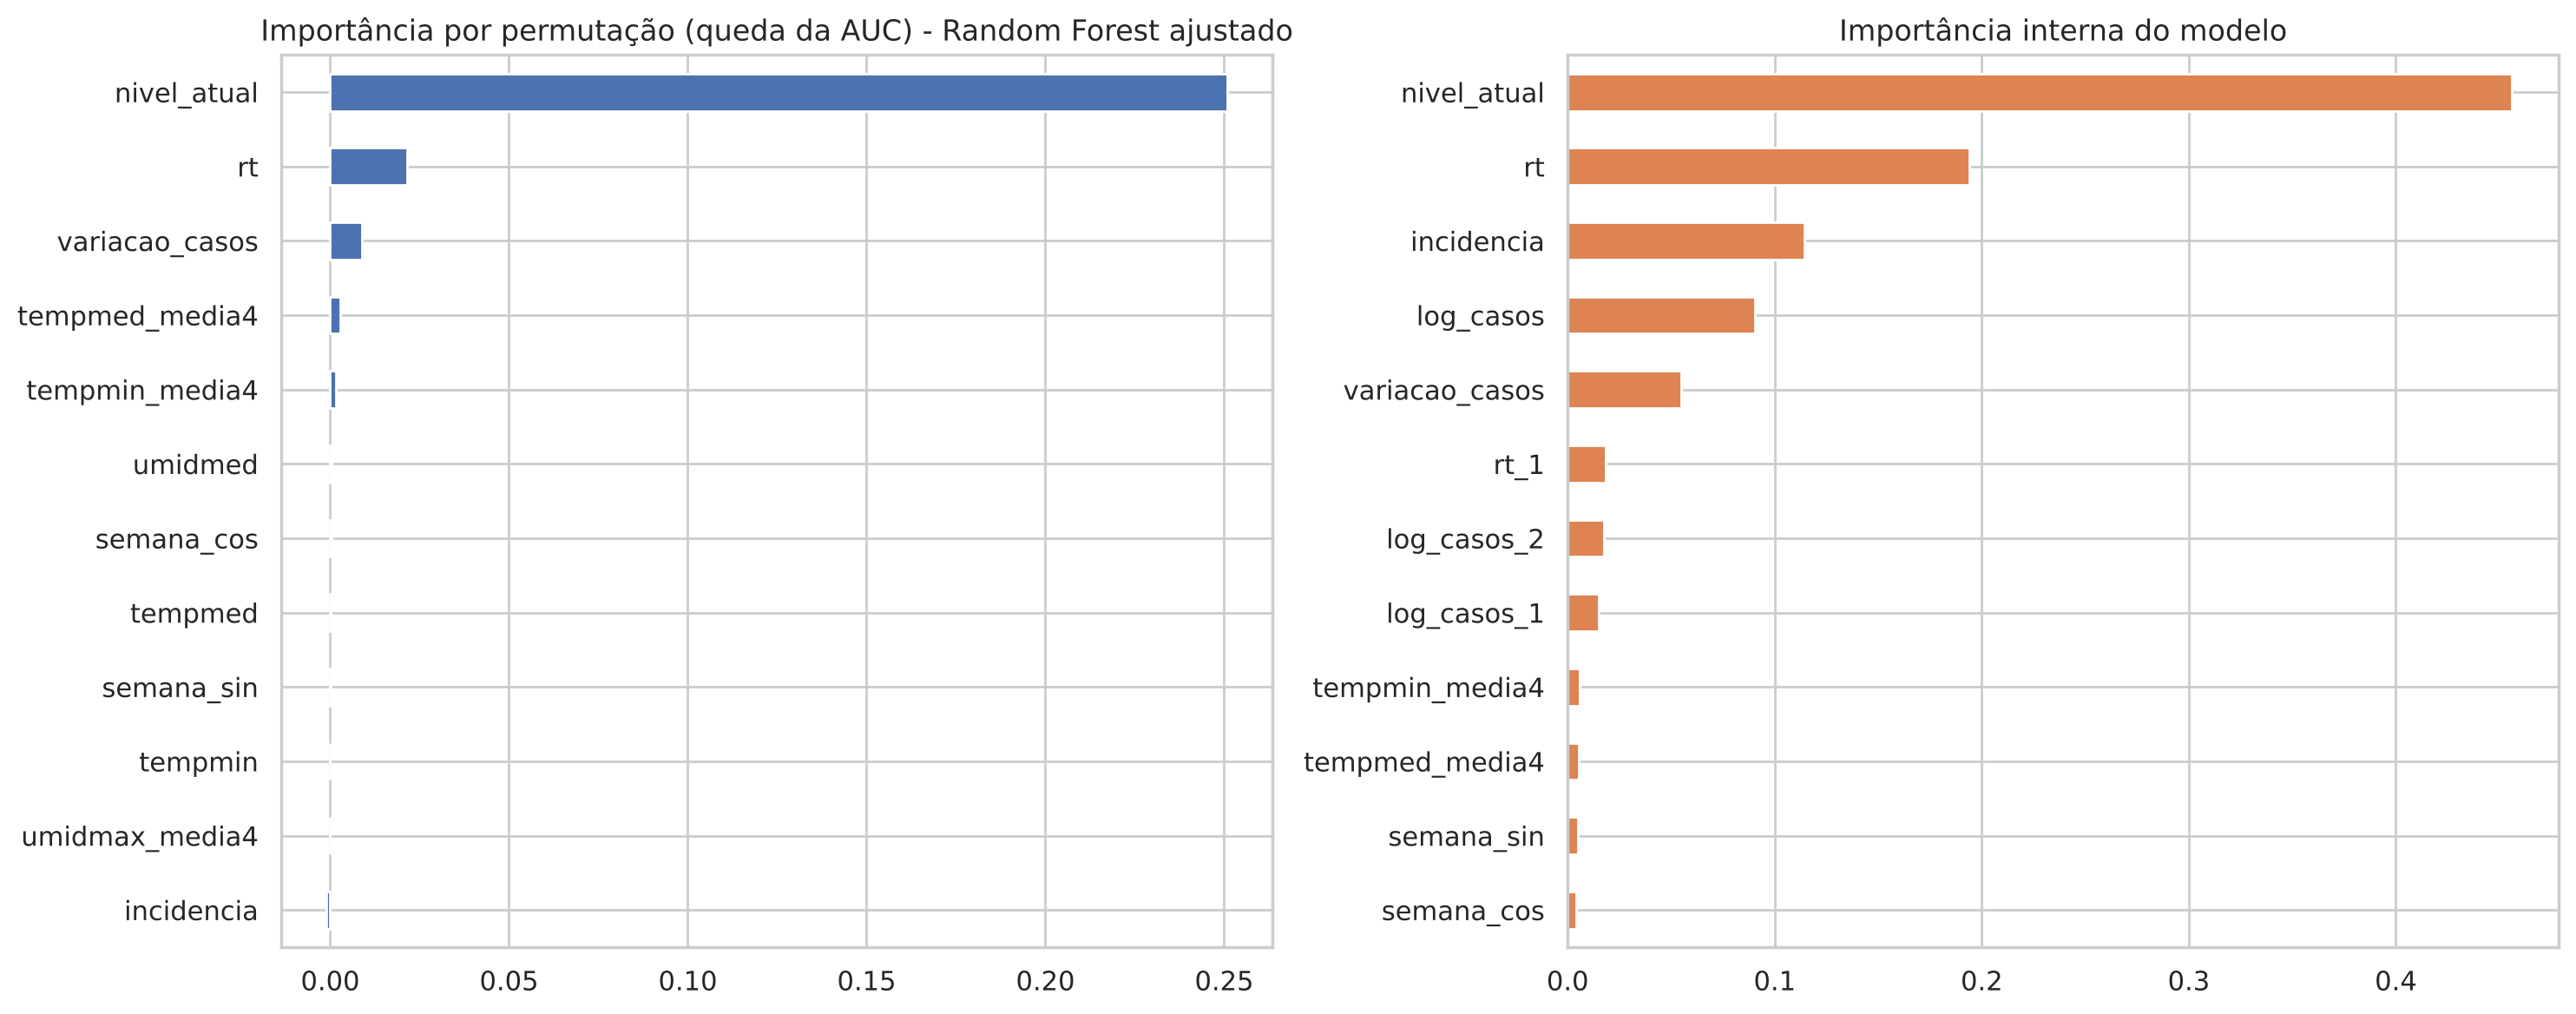

Por permutação (queda da AUC):
nivel_atual       0.2509
rt                0.0215
variacao_casos    0.0088
tempmed_media4    0.0027
tempmin_media4    0.0015
umidmed           0.0005
semana_cos        0.0004
tempmed           0.0002
dtype: float64

Interna do modelo:
nivel_atual       0.4558
rt                0.1941
incidencia        0.1143
log_casos         0.0904
variacao_casos    0.0548
rt_1              0.0185
log_casos_2       0.0176
log_casos_1       0.0148
dtype: float64


In [15]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(modelo_final, X_teste, y_teste, scoring="roc_auc", n_repeats=30, random_state=42)
importancia = pd.Series(imp.importances_mean, index=COLUNAS).sort_values()
fig, eixos = plt.subplots(1, 2, figsize=(15, 6))
importancia.tail(12).plot.barh(ax=eixos[0], color="#4C72B0")
eixos[0].set_title(f"Importância por permutação (queda da AUC) - {nome_final}")
nativa = pd.Series(modelo_final.named_steps["modelo"].feature_importances_, index=COLUNAS).sort_values()
nativa.tail(12).plot.barh(ax=eixos[1], color="#DD8452")
eixos[1].set_title("Importância interna do modelo")
plt.tight_layout(); plt.show()
print("Por permutação (queda da AUC):"); print(importancia.sort_values(ascending=False).head(8).round(4))
print("\nInterna do modelo:"); print(nativa.sort_values(ascending=False).head(8).round(4))

A importância por permutação embaralha uma variável de cada vez no teste e mede quanto a AUC cai. Quanto mais cai, mais o modelo depende dela. A importância interna mostra quanto cada variável foi usada para dividir as árvores.

- **nível atual** é a variável principal nos dois métodos. Faz sentido: o risco muda devagar, e quem está no vermelho costuma continuar.
- **Rt** vem logo depois (19% da importância interna). É o sinal que antecipa as viradas: quando o Rt dispara, os casos vão subir nas próximas semanas, mesmo com o nível ainda baixo.
- **incidência, casos em log e variação dos casos** mostram a tendência recente da doença.
- **clima** (temperatura média das últimas 4 semanas, temperatura mínima e umidade) aparece com peso pequeno. Ele ajuda, mas não decide sozinho, o mesmo que a Estatística mostrou (o clima explica perto de 18% do Rt).

## 10. Demonstração: previsões

### 10.1 Começo da epidemia de 2024 (semanas reais que o modelo não viu no treino)

In [16]:
ultimas = teste[(teste["data"] >= "2023-11-26") & (teste["data"] <= "2024-02-04")].copy()
ultimas["prob_risco_alto"] = modelo_final.predict_proba(ultimas[COLUNAS])[:, 1].round(3)
ultimas["previsto"] = np.where(ultimas["prob_risco_alto"] >= 0.5, "ALTO", "baixo")
ultimas["real_prox_semana"] = ultimas["alvo"].map({0: "baixo", 1: "ALTO"})
ultimas[["data", "nivel_atual", "rt", "tempmed", "prob_risco_alto", "previsto", "real_prox_semana"]]

,data,nivel_atual,rt,tempmed,prob_risco_alto,previsto,real_prox_semana
462,2023-11-26,3,1.245846,21.963557,0.958,ALTO,ALTO
463,2023-12-03,3,1.162359,23.159443,0.930,ALTO,ALTO
464,2023-12-10,3,1.071450,21.877800,0.825,ALTO,baixo
465,2023-12-17,2,0.894579,22.838100,0.169,baixo,baixo
466,2023-12-24,2,1.045661,23.407086,0.180,baixo,baixo
467,2023-12-31,2,2.539555,21.225929,0.759,ALTO,ALTO
468,2024-01-07,4,2.235358,23.790086,0.970,ALTO,ALTO
469,2024-01-14,4,2.064194,24.570771,0.976,ALTO,ALTO
470,2024-01-21,4,2.103112,19.302043,0.979,ALTO,ALTO
471,2024-01-28,4,2.795552,21.652471,0.972,ALTO,ALTO


Olhe a semana de **31/12/2023**: o nível ainda era 2 (amarelo), mas o Rt tinha pulado para 2,54. O modelo deu 76% de chance de risco alto e acertou: era o começo da epidemia recorde de 2024. A persistência teria dito "baixo" e o aviso chegaria uma semana atrasado. Nas semanas de 17 e 24/12 o modelo também acertou a queda para risco moderado.

### 10.2 Como o Alerta Criadouro usa a previsão

A função abaixo junta a previsão da cidade com o que o aparelho mediu no quintal e monta a mensagem para a família.

In [17]:
def mensagem_para_familia(prob_risco_alto, status_quintal):
    risco_cidade = "ALTO" if prob_risco_alto >= 0.5 else "baixo"
    if status_quintal == "ALERTA":
        return f"Risco da cidade {risco_cidade}. Seu potinho está com água há dias: esvazie os recipientes do quintal hoje."
    if status_quintal == "ATENCAO" and risco_cidade == "ALTO":
        return "A dengue deve estar alta na próxima semana e choveu no seu quintal. Faça a vistoria hoje, não espere."
    if status_quintal == "ATENCAO":
        return "Tem água parada no potinho. Dê uma olhada nos vasos e baldes nos próximos dias."
    if risco_cidade == "ALTO":
        return "Quintal seco, ótimo. A dengue está alta na cidade: mantenha a vistoria semanal."
    return "Tudo certo no quintal e risco baixo na cidade."

prob_semana = float(ultimas["prob_risco_alto"].iloc[5])
print("Semana usada:", ultimas["data"].iloc[5].date(), "| probabilidade de risco alto:", prob_semana)
for status in ["OK", "ATENCAO", "ALERTA"]:
    print(f"Quintal {status:8s} -> {mensagem_para_familia(prob_semana, status)}")

Semana usada: 2023-12-31 | probabilidade de risco alto: 0.759
Quintal OK       -> Quintal seco, ótimo. A dengue está alta na cidade: mantenha a vistoria semanal.
Quintal ATENCAO  -> A dengue deve estar alta na próxima semana e choveu no seu quintal. Faça a vistoria hoje, não espere.
Quintal ALERTA   -> Risco da cidade ALTO. Seu potinho está com água há dias: esvazie os recipientes do quintal hoje.


### 10.3 Simulação: começo de um surto

Pegamos uma semana real de risco baixo e simulamos o que acontece se, na semana seguinte, os casos subirem 60%, o Rt passar de 1,4 e o tempo esquentar.

In [18]:
base_sim = teste[teste["data"] == "2025-11-16"].copy()   # semana calma real: nível 1 e Rt 0,87
sim = base_sim.copy()
sim["log_casos_2"] = base_sim["log_casos_1"]; sim["log_casos_1"] = base_sim["log_casos"]
sim["log_casos"] = np.log1p(np.expm1(base_sim["log_casos"]) * 1.6)
sim["variacao_casos"] = sim["log_casos"] - sim["log_casos_1"]
sim["rt_1"] = base_sim["rt"]; sim["rt"] = 1.45
sim["incidencia"] = base_sim["incidencia"] * 1.6
for c in ["tempmed", "tempmed_media4"]: sim[c] = base_sim[c] + 3
comparar = pd.concat([base_sim.assign(cenario="semana real"), sim.assign(cenario="simulação de surto")])
comparar["prob_risco_alto"] = modelo_final.predict_proba(comparar[COLUNAS])[:, 1].round(3)
comparar[["cenario", "data", "nivel_atual", "rt", "variacao_casos", "tempmed", "prob_risco_alto"]]

,cenario,data,nivel_atual,rt,variacao_casos,tempmed,prob_risco_alto
565,semana real,2025-11-16,1,0.867245,-0.186059,20.050957,0.134
565,simulação de surto,2025-11-16,1,1.450000,0.469861,23.050957,0.807


Com a semana calma real (16/11/2025), a chance de risco alto era de 13%. Com os sinais de começo de surto, sobe para 81%, mesmo com o nível atual ainda verde. A persistência continuaria dizendo "baixo".

In [19]:
import joblib
joblib.dump({"modelo": modelo_final, "colunas": COLUNAS, "nome": nome_final}, "modelo_risco_dengue.joblib")
print("Modelo salvo em modelo_risco_dengue.joblib")

Modelo salvo em modelo_risco_dengue.joblib


## 11. Benefício para o público e limitações

**Benefício para as famílias:** o aparelho no quintal passa a saber se a cidade está entrando numa fase perigosa. Nas semanas de risco alto, o aviso de água parada fica mais firme e chega antes. Na prática, mais famílias esvaziam os recipientes na semana que importa. Para os agentes de combate a endemias, a previsão ajuda a planejar mutirões nas semanas de virada.

**Limitações:**
- O modelo prevê o risco da **cidade inteira**, não de cada bairro. Com dados por bairro (que o InfoDengue não dá para São Paulo), a previsão seria mais útil.
- O risco muda devagar, então boa parte do acerto vem da situação atual. O ganho real do modelo está nas viradas, e ele ainda perde várias.
- O treino tem poucos anos de surto forte, e 2024 foi diferente de tudo. Em anos muito fora do padrão o modelo pode errar.
- Os dados do InfoDengue chegam com atraso de notificação: a semana mais recente pode mudar depois.
- **Evoluções futuras:** usar a previsão do tempo das próximas semanas, juntar as leituras de vários aparelhos Alerta Criadouro por bairro e retreinar o modelo todo mês.

**ODS:** 3 (Saúde e bem-estar), 11 (Cidades e comunidades sustentáveis) e 13 (Ação contra a mudança do clima).